In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, f1_score, v_measure_score

RUTA_DATOS = Path("datos")

In [2]:
def verificar_datos(conjunto):
    ruta = RUTA_DATOS / conjunto

    imagenes = sorted((ruta / "imagenes").glob("*.jpg"))
    mascaras = sorted((ruta / "mascaras").glob("*.png"))

    ids_imagenes = {p.stem for p in imagenes}
    ids_mascaras = {
        p.stem.replace("_Segmentation", "")
        for p in mascaras
    }

    print(f"{conjunto.upper()}")
    print(f"Imágenes: {len(imagenes)}")
    print(f"Máscaras: {len(mascaras)}")
    print(f"Parejas completas: {len(ids_imagenes & ids_mascaras)}")
    print(f"Imágenes sin máscara: {ids_imagenes - ids_mascaras}")
    print(f"Máscaras sin imagen: {ids_mascaras - ids_imagenes}")

verificar_datos("ajuste")
verificar_datos("prueba")

AJUSTE
Imágenes: 15
Máscaras: 15
Parejas completas: 15
Imágenes sin máscara: set()
Máscaras sin imagen: set()
PRUEBA
Imágenes: 5
Máscaras: 5
Parejas completas: 5
Imágenes sin máscara: set()
Máscaras sin imagen: set()


Aqui revisamos que no hayan imagenes sin su mascara.

In [3]:

def cargar_imagen(id_imagen, conjunto="ajuste", tamaño=(128, 128)):
    ruta = RUTA_DATOS / conjunto

    ruta_imagen = ruta / "imagenes" / f"{id_imagen}.jpg"
    ruta_mascara = ruta / "mascaras" / f"{id_imagen}_Segmentation.png"

    # Cargar imagen y convertir a RGB
    imagen = Image.open(ruta_imagen).convert("RGB")
    imagen = imagen.resize(tamaño, Image.Resampling.BILINEAR)

    # Cargar máscara y conservar sus valores binarios
    mascara = Image.open(ruta_mascara).convert("L")
    mascara = mascara.resize(tamaño, Image.Resampling.NEAREST)

    imagen = np.array(imagen)
    mascara = (np.array(mascara) > 127).astype(np.uint8)

    return imagen, mascara


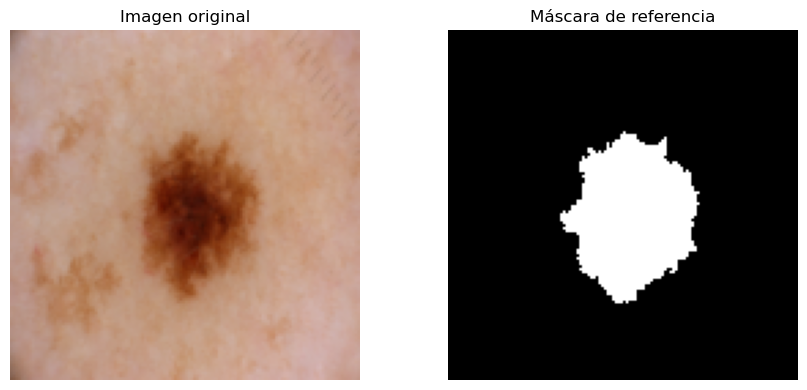

Dimensiones imagen: (128, 128, 3)
Dimensiones máscara: (128, 128)
Valores de máscara: [0 1]


In [4]:

imagen, mascara = cargar_imagen("ISIC_0000085")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara de referencia")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensiones imagen:", imagen.shape)
print("Dimensiones máscara:", mascara.shape)
print("Valores de máscara:", np.unique(mascara))


In [5]:

class RepresentacionPixeles(BaseEstimator, TransformerMixin):

    def __init__(self, beta=1.0, lambda_=0.5):
        self.beta = beta
        self.lambda_ = lambda_

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        alto, ancho, _ = X.shape

        # Normalizar colores entre 0 y 1
        colores = X.reshape(-1, 3).astype(float) / 255.0

        # Coordenadas normalizadas entre 0 y 1
        y, x = np.indices((alto, ancho))

        x = x.ravel() / max(ancho - 1, 1)
        y = y.ravel() / max(alto - 1, 1)

        posiciones = np.column_stack((x, y))

        # Aplicar los pesos beta y lambda
        caracteristicas = np.column_stack((
            self.beta * colores,
            self.lambda_ * posiciones
        ))

        return caracteristicas


pipeline = Pipeline([
    ("representacion", RepresentacionPixeles(beta=1.0, lambda_=0.5))
])

X = pipeline.fit_transform(imagen)

print("Dimensiones de X:", X.shape)
print("Primer píxel:", X[0])


Dimensiones de X: (16384, 5)
Primer píxel: [0.53333333 0.40784314 0.37254902 0.         0.        ]
